# 01 - Data analysis: AI-generated Shorts in child feeds

> **Demo-data notice.** `data/raw/test_run.jsonl` currently contains a small **synthetic** log
> (every record has `"synthetic": true`). It only shows that the pipeline works end to end.
> Replace the file with the real logs (same schema, see `src/make_demo_data.py`) before drawing any conclusions.

This notebook answers the three research questions of the project:

| RQ | Question | Effect we report |
|----|----------|------------------|
| RQ1 | Is the AI share higher in child feeds than in adult feeds? | difference in AI share (percentage points) |
| RQ2 | Does watching AI videos increase the AI share more than watching human videos? | difference in the change of AI share (pp) |
| RQ3 | Does a multimodal detector beat a metadata-only baseline? | gain in macro-F1 |

**Structure:** (1) data ingestion and warm-up filtering, (2) statistical aggregation, (3) visualization and export.
All random steps use seed 42. To reproduce: *Kernel -> Restart & Run All*.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)  # the bootstraps inside src/process_data.py also use seed 42

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import process_data as pdm   # data processing and statistics
import visualize as viz      # figures

pd.set_option("display.width", 160)
print("repo root folder:", ROOT.name)

repo root folder: repo


## 1. Data ingestion and warm-up filtering

A new account has no watch history, so its very first session is a **cold start**: the feed is unstable and not
comparable with later sessions. These sessions are stored in the raw log with `phase = "warmup"` and are
**discarded**; only `phase = "eval"` sessions are analysed.

In [2]:
feeds, videos = pdm.load_raw(ROOT / "data" / "raw" / "test_run.jsonl")
feeds = pdm.add_share(feeds)
print(f"feed sessions: {len(feeds)}   hand-labelled videos: {len(videos)}")
display(feeds.groupby(["phase", "profile_type"]).size().unstack(fill_value=0))

feed sessions: 100   hand-labelled videos: 100


profile_type,adult,child
phase,,
eval,8,72
warmup,8,12


In [3]:
sessions, n_dropped = pdm.drop_warmup(feeds)
print(f"dropped {n_dropped} cold-start warm-up sessions, kept {len(sessions)} evaluation sessions")
display(sessions[["session_id", "profile_type", "arm", "session_idx", "n_ai", "n_unavailable", "ai_share"]].head())

dropped 20 cold-start warm-up sessions, kept 80 evaluation sessions


,session_id,profile_type,arm,session_idx,n_ai,n_unavailable,ai_share
1,c01-0,child,ai_dwell,0,33,5,0.347368
2,c01-1,child,ai_dwell,1,32,3,0.329897
3,c01-2,child,ai_dwell,2,45,1,0.454545
4,c01-3,child,ai_dwell,3,33,3,0.340206
5,c01-4,child,ai_dwell,4,36,2,0.367347


## 2. Statistical aggregation

* **Unit of analysis:** the *session* for RQ1 and the *account* for RQ2 (videos inside one feed are not independent).
* **Dispersion:** mean +- SD, median, p25, p75, p95, p99.
* **Uncertainty:** 95 % percentile bootstrap CI (10 000 resamples, seed 42).
* The **effect size with its CI is the primary result**; the p-value of the one-sided Welch t-test is secondary.

In [4]:
r1 = pdm.rq1(sessions)
display(pd.DataFrame({g: pdm.describe(r1[g] * 100) for g in ["adult", "child"]}).T.round(2)
        .rename_axis("RQ1 profile (AI share, %)"))
lo, hi = (v * 100 for v in r1["ci"])
print(f"RQ1 effect (child - adult): {r1['diff'] * 100:.1f} pp, 95% bootstrap CI [{lo:.1f}, {hi:.1f}]")
print(f"secondary: Welch t = {r1['t']:.2f}, one-sided p = {r1['p']:.2g} (session level)")

RQ1 effect (child - adult): 15.9 pp, 95% bootstrap CI [12.1, 19.9]
secondary: Welch t = 7.57, one-sided p = 5.6e-07 (session level)


,n,mean,sd,median,p25,p75,p95,p99
"RQ1 profile (AI share, %)",,,,,,,,
adult,8.0,13.01,4.44,13.79,10.89,15.85,17.89,18.27
child,12.0,28.89,4.82,28.71,24.49,31.00,36.66,38.53


In [5]:
r2 = pdm.rq2(sessions)
display(pd.DataFrame({a: pdm.describe(x * 100) for a, x in r2["groups"].items()}).T.round(2)
        .rename_axis("RQ2 arm (change in AI share, pp)"))
lo, hi = (v * 100 for v in r2["ci"])
print(f"RQ2 effect (AI-dwell - human-dwell): {r2['diff'] * 100:.1f} pp, 95% bootstrap CI [{lo:.1f}, {hi:.1f}]")
print(f"secondary: Welch t = {r2['t']:.2f}, one-sided p = {r2['p']:.2g} (account level); no-dwell is an extra control")

RQ2 effect (AI-dwell - human-dwell): 17.8 pp, 95% bootstrap CI [14.0, 22.1]
secondary: Welch t = 7.45, one-sided p = 0.0003 (account level); no-dwell is an extra control


,n,mean,sd,median,p25,p75,p95,p99
"RQ2 arm (change in AI share, pp)",,,,,,,,
ai_dwell,4.0,16.85,4.00,16.10,15.14,17.81,21.47,22.20
human_dwell,4.0,-0.97,2.62,-0.62,-2.36,0.76,1.48,1.62
no_dwell,4.0,4.23,6.09,4.84,1.11,7.96,10.15,10.58


In [6]:
r3 = pdm.rq3(videos)
table = pd.DataFrame([
    {"feature set": k, **{m: v[m] for m in ["macro_f1", "macro_precision", "macro_recall"]},
     "ci_low": v["ci"][0], "ci_high": v["ci"][1]}
    for k, v in r3["sets"].items()]).set_index("feature set")
display(table.round(3))
print(f"train videos: {r3['n_train']}, test videos: {r3['n_test']}")
print(f"RQ3 gain (multimodal - metadata-only): {r3['gain']:.3f}, 95% bootstrap CI "
      f"[{r3['gain_ci'][0]:.3f}, {r3['gain_ci'][1]:.3f}]; threshold 0.05 reached: {r3['gain_reaches_threshold']}")

train videos: 60, test videos: 40
RQ3 gain (multimodal - metadata-only): 0.294, 95% bootstrap CI [0.126, 0.467]; threshold 0.05 reached: True


,macro_f1,macro_precision,macro_recall,ci_low,ci_high
feature set,,,,,
metadata_only,0.581,0.716,0.625,0.413,0.725
visual,0.875,0.876,0.875,0.750,0.974
audio,0.591,0.610,0.600,0.427,0.733
multimodal,0.875,0.876,0.875,0.750,0.974


In [7]:
guards = pd.DataFrame(pdm.guardrails(sessions, videos))
display(guards.round(3))

,metric,group,n,value,note
0,error_rate_unavailable_pct,adult,8,2.00,PASS (<= 5%)
1,error_rate_unavailable_pct,child,72,2.00,PASS (<= 5%)
2,cohen_kappa,double-coded videos,100,0.76,PASS (>= 0.7)
3,baseline_sessions,adult,8,8.00,PASS (>= 3)
4,baseline_sessions,child,12,12.00,PASS (>= 3)
5,accounts_per_arm,ai_dwell,4,4.00,PASS (>= 3)
6,accounts_per_arm,human_dwell,4,4.00,PASS (>= 3)
7,accounts_per_arm,no_dwell,4,4.00,PASS (>= 3)


## 3. Visualization and export

Every figure has labelled axes with units, a 95 % bootstrap CI, a colour-blind-safe palette with different
markers / line styles / hatches, and is saved as vector `.pdf` and `.png` (300 DPI) in `reports/figures/`.

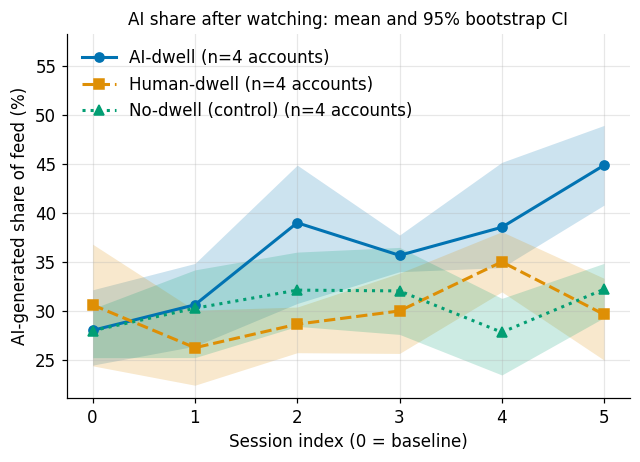

In [8]:
summary, res = pdm.build_summary()
fig1 = viz.make_fig1(res["trajectory"])
viz.save_figure(fig1, "fig1_ai_share_vs_session")
plt.show()

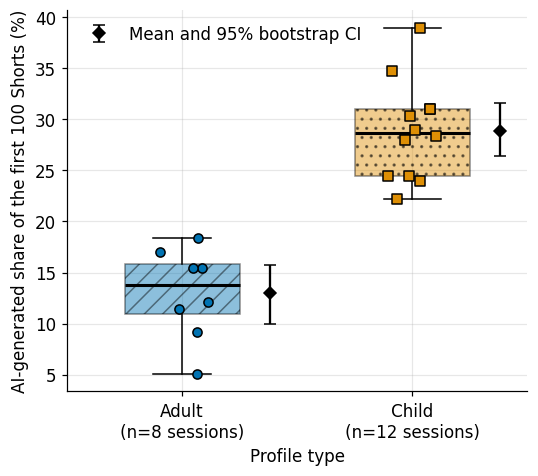

In [9]:
fig2 = viz.make_fig2(res["rq1"])
viz.save_figure(fig2, "fig2_distribution_boxplot")
plt.show()

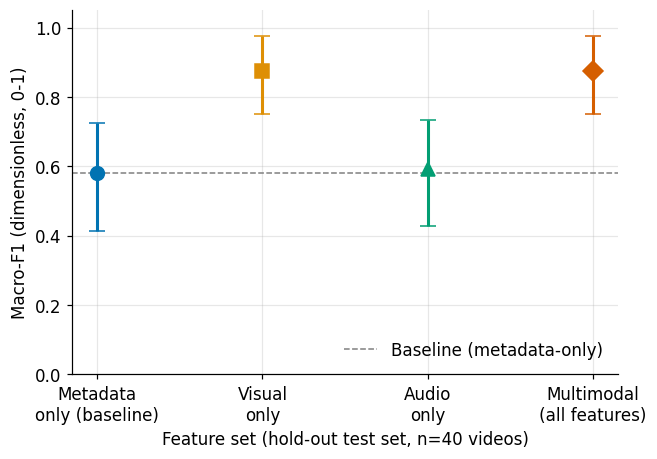

In [10]:
fig3 = viz.make_fig3(res["rq3"])
viz.save_figure(fig3, "fig3_f1_by_feature_set")
plt.show()

In [11]:
out = pdm.save_summary(summary)
print("saved", out.relative_to(ROOT))
display(summary[summary["metric"].str.contains("diff|gain")][["rq", "metric", "value", "ci_low", "ci_high", "note"]].round(3))

saved data/processed/metrics_summary.csv


,rq,metric,value,ci_low,ci_high,note
15,RQ1,diff_child_minus_adult_pp,15.875,12.135,19.871,"Welch t=7.57, one-sided p=5.6e-07 (session level)"
37,RQ2,diff_aidwell_minus_humandwell_pp,17.825,14.024,22.058,"Welch t=7.45, one-sided p=0.0003 (account level)"
50,RQ3,gain_multimodal_minus_metadata,0.294,0.126,0.467,threshold 0.05: reached (point estimate)


## 4. How to read the results

* RQ1, RQ2 and RQ3 are judged by the **effect size and its 95 % CI**, not by the p-value alone.
* With few sessions, accounts and test videos the CIs are wide; more real data will narrow them.
* The numbers above come from **synthetic demo data** and say nothing about YouTube yet.